In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent(f, df, x0, learning_rate=0.1, max_iter=100, tol=1e-6):
    """
    Trouve le minimum d'une fonction par descente de gradient

    Args:
        f: fonction à minimiser
        df: dérivée de la fonction
        x0: point de départ
        learning_rate: taux d'apprentissage (eta)
        max_iter: nombre maximum d'itérations
        tol: tolérance pour l'arrêt

    Returns:
        history: liste des positions visitées
        values: liste des valeurs de f
    """
    history = [x0]
    values = [f(x0)]
    x = x0

    for i in range(max_iter):
        # Calcul du gradient
        grad = df(x)

        # Mise à jour
        x_new = x - learning_rate * grad

        # Sauvegarde
        history.append(x_new)
        values.append(f(x_new))

        # Critère d'arrêt
        if abs(x_new - x) < tol:
            print(f"Convergence atteinte en {i+1} itérations")
            break

        x = x_new

    return np.array(history), np.array(values)


# Définition de la fonction et sa dérivée
# Exemple: f(x) = x² - 4x + 5
def f(x):
    return x**2 - 4*x + 5

def df(x):
    return 2*x - 4




In [2]:
# Paramètres
x0 = 0  # Point de départ
learning_rate = 0.1
max_iter = 100

# Exécution de la descente de gradient
history, values = gradient_descent(f, df, x0, learning_rate, max_iter)

print(f"Point de départ: x0 = {x0}")
print(f"Minimum trouvé: x* = {history[-1]:.6f}")
print(f"Valeur minimale: f(x*) = {values[-1]:.6f}")
print(f"Nombre d'itérations: {len(history)-1}")



Convergence atteinte en 59 itérations
Point de départ: x0 = 0
Minimum trouvé: x* = 1.999996
Valeur minimale: f(x*) = 1.000000
Nombre d'itérations: 59


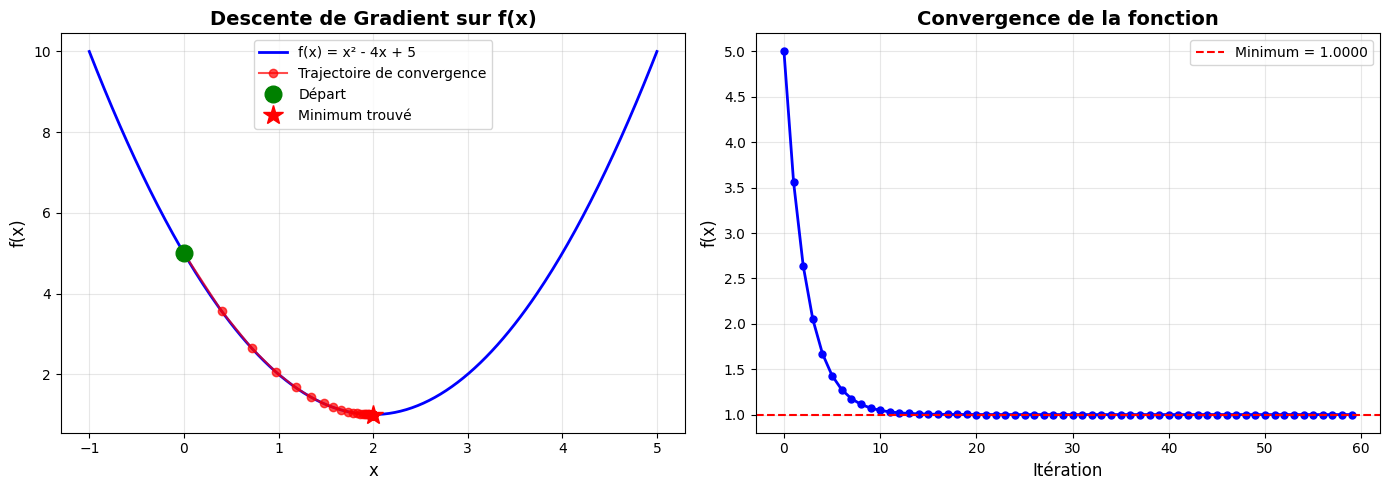


--- Premières itérations ---
Itération 0: x = 0.0000, f(x) = 5.0000, gradient = -4.0000
Itération 1: x = 0.4000, f(x) = 3.5600, gradient = -3.2000
Itération 2: x = 0.7200, f(x) = 2.6384, gradient = -2.5600
Itération 3: x = 0.9760, f(x) = 2.0486, gradient = -2.0480
Itération 4: x = 1.1808, f(x) = 1.6711, gradient = -1.6384
Itération 5: x = 1.3446, f(x) = 1.4295, gradient = -1.3107
Itération 6: x = 1.4757, f(x) = 1.2749, gradient = -1.0486
Itération 7: x = 1.5806, f(x) = 1.1759, gradient = -0.8389
Itération 8: x = 1.6645, f(x) = 1.1126, gradient = -0.6711
Itération 9: x = 1.7316, f(x) = 1.0721, gradient = -0.5369


In [3]:
# Visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Fonction et trajectoire de convergence
x_range = np.linspace(-1, 5, 300)
y_range = f(x_range)

ax1.plot(x_range, y_range, 'b-', linewidth=2, label='f(x) = x² - 4x + 5')
ax1.plot(history, values, 'ro-', markersize=6, linewidth=1.5,
         alpha=0.7, label='Trajectoire de convergence')
ax1.plot(history[0], values[0], 'go', markersize=12, label='Départ')
ax1.plot(history[-1], values[-1], 'r*', markersize=15, label='Minimum trouvé')

ax1.set_xlabel('x', fontsize=12)
ax1.set_ylabel('f(x)', fontsize=12)
ax1.set_title('Descente de Gradient sur f(x)', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Convergence (valeur de f au fil des itérations)
iterations = np.arange(len(values))
ax2.plot(iterations, values, 'b-o', linewidth=2, markersize=5)
ax2.axhline(y=values[-1], color='r', linestyle='--',
            label=f'Minimum = {values[-1]:.4f}')

ax2.set_xlabel('Itération', fontsize=12)
ax2.set_ylabel('f(x)', fontsize=12)
ax2.set_title('Convergence de la fonction', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Affichage des premières itérations
print("\n--- Premières itérations ---")
for i in range(min(10, len(history))):
    print(f"Itération {i}: x = {history[i]:.4f}, f(x) = {values[i]:.4f}, "
          f"gradient = {df(history[i]):.4f}")

LR = 0.01: Convergence en 50 itérations, x* = 1.2717, f(x*) = 1.5305
LR = 0.1: Convergence en 50 itérations, x* = 2.0000, f(x*) = 1.0000
Convergence atteinte en 2 itérations
LR = 0.5: Convergence en 2 itérations, x* = 2.0000, f(x*) = 1.0000
LR = 0.9: Convergence en 50 itérations, x* = 2.0000, f(x*) = 1.0000
LR = 1.1: Convergence en 50 itérations, x* = -18198.8763, f(x*) = 331271899.0881


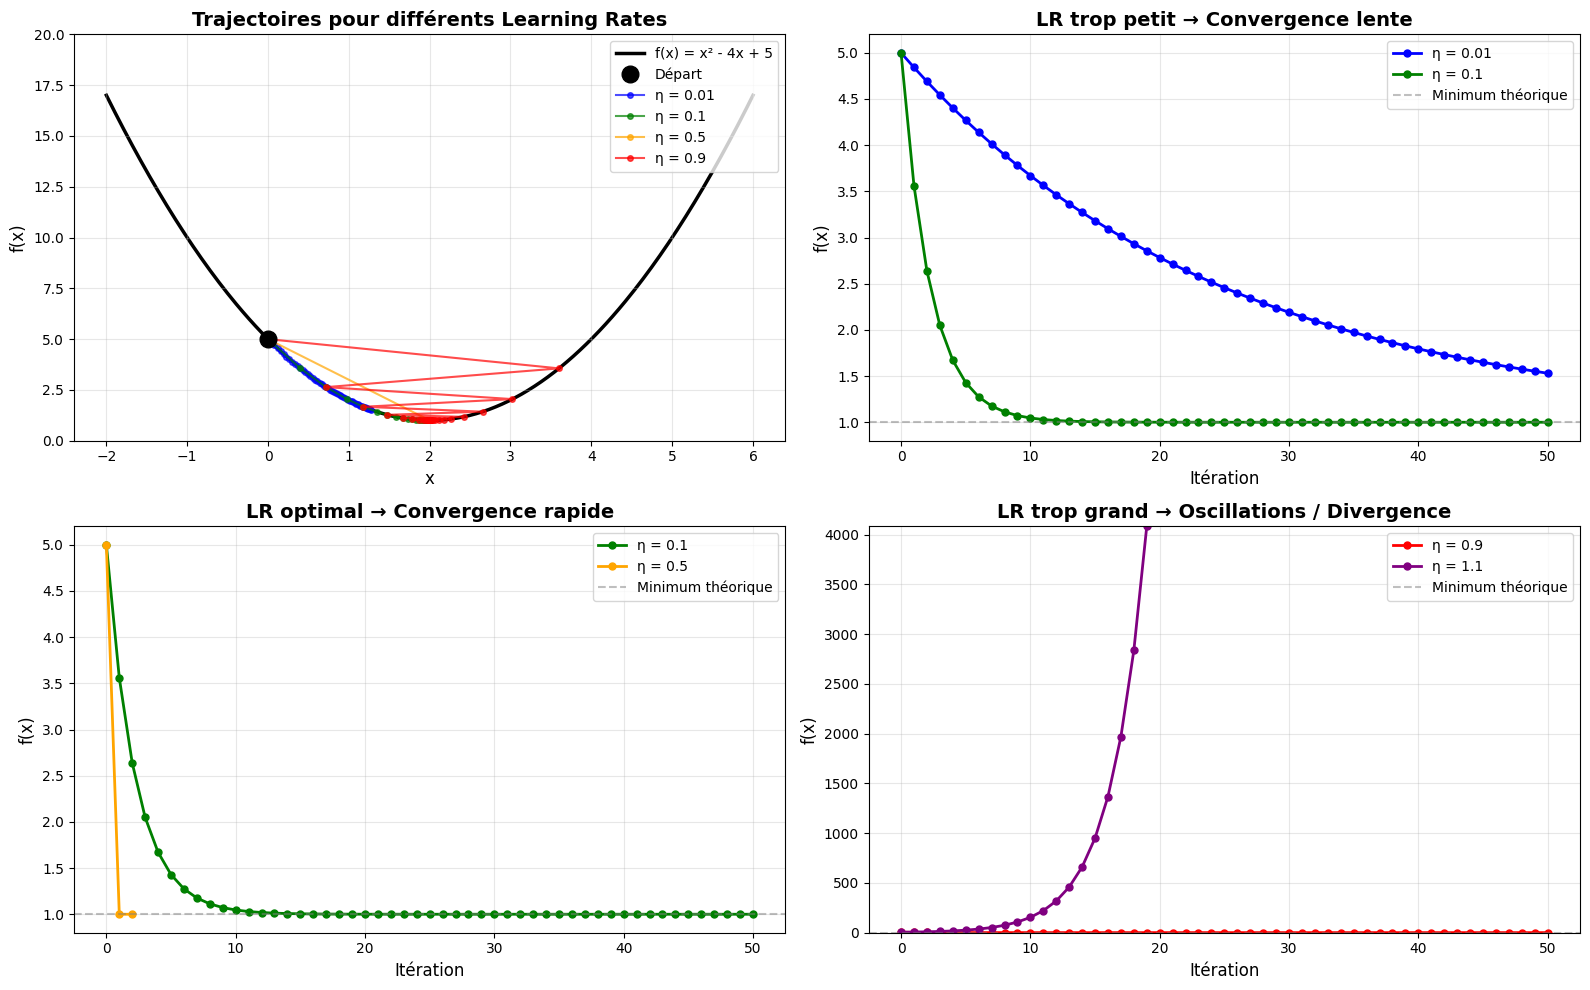


ANALYSE DES LEARNING RATES

Learning Rate η = 0.01:
  • Nombre d'itérations: 50
  • Position finale: x = 1.271661
  • Valeur finale: f(x) = 1.530478
  ➜ TROP PETIT: Convergence lente mais stable

Learning Rate η = 0.1:
  • Nombre d'itérations: 50
  • Position finale: x = 1.999971
  • Valeur finale: f(x) = 1.000000
  ➜ TROP PETIT: Convergence lente mais stable

Learning Rate η = 0.5:
  • Nombre d'itérations: 2
  • Position finale: x = 2.000000
  • Valeur finale: f(x) = 1.000000
  ➜ OPTIMAL: Convergence rapide et stable

Learning Rate η = 0.9:
  • Nombre d'itérations: 50
  • Position finale: x = 1.999971
  • Valeur finale: f(x) = 1.000000
  ➜ LIMITE: Oscillations importantes

Learning Rate η = 1.1:
  • Nombre d'itérations: 50
  • Position finale: x = -18198.876300
  • Valeur finale: f(x) = 331271899.088064
  ➜ TROP GRAND: Divergence ou oscillations extrêmes


In [4]:
# Paramètres à tester
x0 = 0  # Point de départ
learning_rates = [0.01, 0.1, 0.5, 0.9, 1.1]
max_iter = 50

# Couleurs pour les différents learning rates
colors = ['blue', 'green', 'orange', 'red', 'purple']

# Exécution pour chaque learning rate
results = {}
for lr in learning_rates:
    history, values = gradient_descent(f, df, x0, lr, max_iter)
    results[lr] = (history, values)
    print(f"LR = {lr}: Convergence en {len(history)-1} itérations, "
          f"x* = {history[-1]:.4f}, f(x*) = {values[-1]:.4f}")

# Visualisation
fig = plt.figure(figsize=(16, 10))

# Plot 1: Fonction et trajectoires
ax1 = plt.subplot(2, 2, 1)
x_range = np.linspace(-2, 6, 300)
y_range = f(x_range)

ax1.plot(x_range, y_range, 'k-', linewidth=2.5, label='f(x) = x² - 4x + 5', zorder=1)
ax1.plot(x0, f(x0), 'ko', markersize=12, label='Départ', zorder=5)

for i, lr in enumerate(learning_rates[:4]):
    history, values = results[lr]
    ax1.plot(history, values, 'o-', color=colors[i], markersize=4,
             linewidth=1.5, alpha=0.7, label=f'η = {lr}', zorder=3)

ax1.set_xlabel('x', fontsize=12)
ax1.set_ylabel('f(x)', fontsize=12)
ax1.set_title('Trajectoires pour différents Learning Rates', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0, 20])

# Plot 2: Convergence (Learning rate trop petit)
ax2 = plt.subplot(2, 2, 2)
for i, lr in enumerate([0.01, 0.1]):
    history, values = results[lr]
    iterations = np.arange(len(values))
    ax2.plot(iterations, values, 'o-', color=colors[i], linewidth=2,
             markersize=5, label=f'η = {lr}')

ax2.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='Minimum théorique')
ax2.set_xlabel('Itération', fontsize=12)
ax2.set_ylabel('f(x)', fontsize=12)
ax2.set_title('LR trop petit → Convergence lente', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Convergence (Learning rate optimal)
ax3 = plt.subplot(2, 2, 3)
for i, lr in enumerate([0.1, 0.5]):
    history, values = results[lr]
    iterations = np.arange(len(values))
    ax3.plot(iterations, values, 'o-', color=colors[i+1], linewidth=2,
             markersize=5, label=f'η = {lr}')

ax3.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='Minimum théorique')
ax3.set_xlabel('Itération', fontsize=12)
ax3.set_ylabel('f(x)', fontsize=12)
ax3.set_title('LR optimal → Convergence rapide', fontsize=14, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Convergence (Learning rate trop grand)
ax4 = plt.subplot(2, 2, 4)
for i, lr in enumerate([0.9, 1.1]):
    history, values = results[lr]
    iterations = np.arange(len(values))
    ax4.plot(iterations, values, 'o-', color=colors[i+3], linewidth=2,
             markersize=5, label=f'η = {lr}')

ax4.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='Minimum théorique')
ax4.set_xlabel('Itération', fontsize=12)
ax4.set_ylabel('f(x)', fontsize=12)
ax4.set_title('LR trop grand → Oscillations / Divergence', fontsize=14, fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)
ax4.set_ylim([0, max(50, max(results[1.1][1][:20]))])

plt.tight_layout()
plt.show()

# Analyse détaillée
print("\n" + "="*60)
print("ANALYSE DES LEARNING RATES")
print("="*60)

for lr in learning_rates:
    history, values = results[lr]
    print(f"\nLearning Rate η = {lr}:")
    print(f"  • Nombre d'itérations: {len(history)-1}")
    print(f"  • Position finale: x = {history[-1]:.6f}")
    print(f"  • Valeur finale: f(x) = {values[-1]:.6f}")

    if lr <= 0.1:
        print(f"  ➜ TROP PETIT: Convergence lente mais stable")
    elif lr <= 0.7:
        print(f"  ➜ OPTIMAL: Convergence rapide et stable")
    elif lr < 1.0:
        print(f"  ➜ LIMITE: Oscillations importantes")
    else:
        print(f"  ➜ TROP GRAND: Divergence ou oscillations extrêmes")